# Fundamentos de Ingeniería de Datos
## MODELO PREDICTIVO: ¿Cuánto vale mi carro?

```
SERVING                                  MODELO PREDICTIVO (este notebook)
serving.db (esquema estrella)     →      consulta fact_listings + dimensiones
                                         → regresión lineal vs. árbol de decisión
                                         → métricas, tamaño y velocidad de cada uno
```

El modelo recibe las **características de un auto** (marca, modelo, antigüedad, millaje, motor, historial…) y predice su **precio** (`price`, en USD).

Se comparan dos modelos de scikit-learn:

| Modelo | Idea | Ventaja esperada |
|---|---|---|
| **Regresión lineal** | El precio es una suma ponderada de las características | Simple, rápida, fácil de explicar y muy ligera |
| **Árbol de decisión** | Divide los autos en grupos con preguntas sí/no y predice el precio promedio de cada grupo | Capta relaciones no lineales (por ejemplo, la depreciación es más rápida los primeros años) |

> Durante la comparación cada modelo se guarda en una carpeta temporal solo para medir cuánto pesa. Al final (PASO 11) **solo el modelo elegido** se guarda en `streamlit/modelo.joblib`.

### Configuración del entorno

In [1]:
# ── Importar utils.py ──────────────────────────────────────────────────────

import sys
import os
sys.path.append(os.path.abspath('../Utilidades'))   # el notebook se ejecuta desde Codigos/

from utils import PROYECTO_BASE, SERVING_DB, STREAMLIT_PATH, ruta_relativa, tamano_mb

print()
print('utils.py importado correctamente')
print(f'Proyecto base: {os.path.basename(PROYECTO_BASE)}/')
print()


utils.py importado correctamente
Proyecto base: ING_BD_ProjectF/



In [2]:
# ── Librerías ──────────────────────────────────────────────────────────────

import time
import tempfile
import duckdb
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

pd.set_option('display.max_columns', None)

SEMILLA = 42                                         # misma partición y mismo árbol en cada ejecución

print()
print(f'scikit-learn {sklearn.__version__}  |  DuckDB {duckdb.__version__}')
print()


scikit-learn 1.9.1  |  DuckDB 2.0.1



---
## PASO 1 — Leer los datos desde `serving.db`

El modelo se entrena con la capa **SERVING**, igual que la app. La consulta une `fact_listings` con las dimensiones que aportan las características del auto. `serving.db` se abre en **solo lectura**.

In [3]:
# ── Consulta: hechos + dimensiones ─────────────────────────────────────────

CONSULTA = '''
    SELECT v.manufacturer, v.base_model, v.brand_country, v.brand_segment,
           y.age,
           f.mileage, f.mileage_per_year,
           p.engine_liters, p.cylinders, p.turbo, p.transmission, p.drivetrain, p.fuel_type,
           f.mpg_city, f.mpg_highway,
           ce.color AS exterior_color, ci.color AS interior_color,
           h.accidents_or_damage, h.one_owner, h.personal_use_only,
           f.price
    FROM fact_listings AS f
    JOIN dim_vehicle    AS v  USING (vehicle_id)
    JOIN dim_year       AS y  USING (year)
    JOIN dim_powertrain AS p  USING (powertrain_id)
    JOIN dim_color      AS ce ON ce.color_id = f.exterior_color_id
    JOIN dim_color      AS ci ON ci.color_id = f.interior_color_id
    JOIN dim_history    AS h  USING (history_id)
'''

con = duckdb.connect(SERVING_DB, read_only=True)
datos = con.sql(CONSULTA).df()
con.close()

print()
print(f'Datos leídos de {ruta_relativa(SERVING_DB)}: {datos.shape[0]:,} anuncios, {datos.shape[1]} columnas')
print()

datos.head()


Datos leídos de Modelado_de_Datos/serving.db: 189,845 anuncios, 21 columnas



,manufacturer,base_model,brand_country,brand_segment,age,mileage,mileage_per_year,engine_liters,cylinders,turbo,transmission,drivetrain,fuel_type,mpg_city,mpg_highway,exterior_color,interior_color,accidents_or_damage,one_owner,personal_use_only,price
0,GMC,Sierra,USA,Mainstream,4,99856,24964,5.3,8,False,Automatic,4WD,Gasoline,15.0,21.0,Silver,Black,False,False,True,39000
1,Ford,F-150,USA,Mainstream,2,14179,7090,3.5,6,True,Automatic,4WD,Hybrid,18.0,23.0,Black,Black,False,True,True,56384
2,Cadillac,XT5,USA,Luxury,3,39209,13070,3.6,6,False,Automatic,AWD,Gasoline,19.0,26.0,Unknown,Black,False,True,False,35900
3,Nissan,Murano,Japan,Mainstream,4,66635,16659,3.5,6,False,CVT,AWD,Gasoline,20.0,28.0,Black,Gray,False,True,False,22898
4,Toyota,RAV4,Japan,Mainstream,2,12065,6032,2.5,4,False,CVT,AWD,Hybrid,41.0,38.0,White,Black,False,True,True,37487


---
## PASO 2 — Variables del modelo

| Grupo | Columnas | ¿Entra al modelo? |
|---|---|---|
| **Objetivo** | `price` | Es lo que se predice |
| **Categóricas** | `manufacturer`, `base_model`, `brand_country`, `brand_segment`, `transmission`, `drivetrain`, `fuel_type`, `exterior_color`, `interior_color` | ✅ |
| **Numéricas** | `age`, `mileage`, `mileage_per_year`, `engine_liters`, `cylinders`, `mpg_city`, `mpg_highway` | ✅ |
| **Sí/no** | `turbo`, `accidents_or_damage`, `one_owner`, `personal_use_only` | ✅ (como 0/1) |
| No se usan | `model` (versión: ~7,300 valores, demasiado detalle), `year` (es lo mismo que `age`), `mileage_km` (es lo mismo que `mileage`) | Redundantes |
| No se usan | `price_drop`, `original_price`, `price_range` | Se derivan del precio: sería *data leakage* |
| No se usan | `seller_name`, `seller_rating`, `driver_rating`, `driver_reviews_num` | Informativas: el usuario no las puede capturar |

In [4]:
# ── Definir variables ──────────────────────────────────────────────────────

OBJETIVO     = 'price'
CATEGORICAS  = ['manufacturer', 'base_model', 'brand_country', 'brand_segment',
                'transmission', 'drivetrain', 'fuel_type', 'exterior_color', 'interior_color']
NUMERICAS    = ['age', 'mileage', 'mileage_per_year', 'engine_liters', 'cylinders', 'mpg_city', 'mpg_highway']
BOOLEANAS    = ['turbo', 'accidents_or_damage', 'one_owner', 'personal_use_only']

X = datos[CATEGORICAS + NUMERICAS + BOOLEANAS].copy()
X[BOOLEANAS] = X[BOOLEANAS].astype(int)                     # True/False → 1/0
y = datos[OBJETIVO]

print()
print(f'Variables de entrada : {X.shape[1]}  ({len(CATEGORICAS)} categóricas, {len(NUMERICAS)} numéricas, {len(BOOLEANAS)} sí/no)')
print(f'Valores distintos    : {X[CATEGORICAS].nunique().to_dict()}')
print()


Variables de entrada : 20  (9 categóricas, 7 numéricas, 4 sí/no)
Valores distintos    : {'manufacturer': 30, 'base_model': 605, 'brand_country': 6, 'brand_segment': 2, 'transmission': 3, 'drivetrain': 4, 'fuel_type': 7, 'exterior_color': 15, 'interior_color': 14}



### ¿Cómo se distribuye el precio?

Una regresión lineal supone que los errores son parecidos en autos baratos y caros. El precio está **sesgado a la derecha** (muchos autos baratos y pocos caros), y la depreciación es **porcentual**: un auto pierde cierto % de su valor por año, no una cantidad fija. Por eso la regresión lineal se entrena sobre el **logaritmo** del precio y su predicción se regresa a dólares. El árbol no necesita esta transformación.

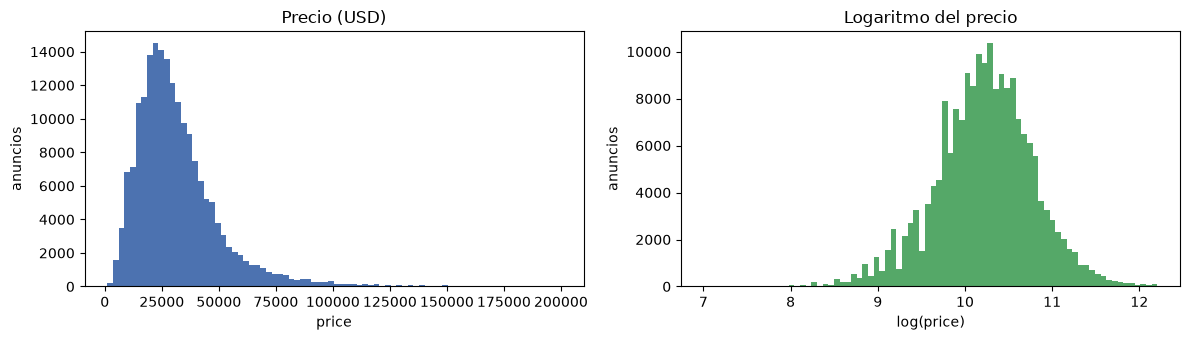

In [5]:
# ── Distribución del precio: original vs. logaritmo ────────────────────────

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))

ejes[0].hist(y, bins=80, color='#4C72B0')
ejes[0].set_title('Precio (USD)')
ejes[0].set_xlabel('price')

ejes[1].hist(np.log(y), bins=80, color='#55A868')
ejes[1].set_title('Logaritmo del precio')
ejes[1].set_xlabel('log(price)')

for eje in ejes:
    eje.set_ylabel('anuncios')
plt.tight_layout()
plt.show()

---
## PASO 3 — Partición de entrenamiento y prueba

El modelo aprende con el **80 %** de los anuncios (entrenamiento) y se evalúa con el **20 %** que nunca vio (prueba). Así las métricas miden cómo predice autos **nuevos**, que es lo que hará en la app.

In [6]:
# ── Partición 80 / 20 ──────────────────────────────────────────────────────

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)

print()
print(f'Entrenamiento : {len(X_train):,} anuncios')
print(f'Prueba        : {len(X_test):,} anuncios')
print()


Entrenamiento : 151,876 anuncios
Prueba        : 37,969 anuncios



---
## PASO 4 — Preparación de las variables (*pipelines*)

Cada modelo necesita las variables en una forma distinta. Un `Pipeline` junta la preparación y el modelo en **un solo objeto**: la app solo tendrá que pasarle las características del auto tal como las captura el usuario.

| Paso | Regresión lineal | Árbol de decisión |
|---|---|---|
| Categóricas | **One-hot**: una columna 0/1 por categoría. Las categorías con menos de 20 anuncios se agrupan como "poco frecuentes" | **Ordinal**: cada categoría se vuelve un número (el árbol solo pregunta "¿es menor que…?") |
| Numéricas | **Estandarizar** (media 0, desviación 1) | Sin cambios (al árbol no le afecta la escala) |
| Objetivo | `log(price)` y la predicción se regresa con `exp()` | `price` tal cual |
| Categoría nunca vista en la app | Se ignora (todas sus columnas en 0) | Se codifica como -1 |

In [7]:
# ── Preparación para cada modelo ───────────────────────────────────────────

prep_lineal = ColumnTransformer([
    ('categoricas', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20), CATEGORICAS),
    ('numericas',   StandardScaler(), NUMERICAS),
    ('booleanas',   'passthrough',    BOOLEANAS),
])

prep_arbol = ColumnTransformer([
    ('categoricas', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), CATEGORICAS),
    ('resto',       'passthrough', NUMERICAS + BOOLEANAS),
])

print()
print('Preparaciones listas')
print()


Preparaciones listas



In [8]:
# ── Funciones para evaluar los dos modelos igual ───────────────────────────

def evaluar(nombre, modelo, segundos_entrenamiento):
    '''Calcula métricas en entrenamiento y prueba, velocidad de predicción y tamaño del archivo.'''
    pred_train = modelo.predict(X_train)

    inicio    = time.perf_counter()
    pred_test = modelo.predict(X_test)
    seg_pred  = time.perf_counter() - inicio

    # Tamaño: se guarda en una carpeta temporal del sistema (fuera del proyecto) y se borra
    with tempfile.TemporaryDirectory() as tmp:
        ruta = os.path.join(tmp, 'modelo.joblib')
        joblib.dump(modelo, ruta, compress=3)
        mb = tamano_mb(ruta)

    return {
        'modelo'              : nombre,
        'R2_entrenamiento'    : r2_score(y_train, pred_train),
        'R2_prueba'           : r2_score(y_test, pred_test),
        'MAE_prueba_USD'      : mean_absolute_error(y_test, pred_test),
        'RMSE_prueba_USD'     : root_mean_squared_error(y_test, pred_test),
        'MAPE_prueba_pct'     : mean_absolute_percentage_error(y_test, pred_test) * 100,
        'seg_entrenamiento'   : segundos_entrenamiento,
        'ms_por_1000_autos'   : seg_pred / len(X_test) * 1000 * 1000,
        'MB_joblib'           : mb,
    }, pred_test


def entrenar(modelo):
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    return time.perf_counter() - inicio


print()
print('evaluar() y entrenar() listas')
print()


evaluar() y entrenar() listas



### ¿Qué significa cada métrica?

| Métrica | Pregunta que responde | Mejor |
|---|---|---|
| **R²** | ¿Qué parte de la variación del precio explica el modelo? (1 = todo) | Más alto |
| **MAE** | ¿Por cuántos dólares se equivoca en promedio? | Más bajo |
| **RMSE** | Como el MAE, pero castiga más los errores grandes | Más bajo |
| **MAPE** | ¿Por qué porcentaje del precio se equivoca en promedio? | Más bajo |
| R² entrenamiento vs. prueba | Si el de entrenamiento es mucho mayor, el modelo **memorizó** (*sobreajuste*) | Parecidos |

---
## PASO 5 — Regresión lineal

In [9]:
# ── Regresión lineal sobre log(price) ──────────────────────────────────────

modelo_lineal = Pipeline([
    ('preparacion', prep_lineal),
    ('regresion',   TransformedTargetRegressor(regressor=LinearRegression(),
                                               func=np.log, inverse_func=np.exp)),
])

seg = entrenar(modelo_lineal)
metricas_lineal, pred_lineal = evaluar('Regresión lineal', modelo_lineal, seg)

n_columnas = modelo_lineal.named_steps['preparacion'].transform(X_train.head(1)).shape[1]

print()
print(f'Columnas después de one-hot: {n_columnas:,}')
print()
pd.Series(metricas_lineal).to_frame('valor')


Columnas después de one-hot: 514



,valor
modelo,Regresión lineal
R2_entrenamiento,0.886965
R2_prueba,0.887819
MAE_prueba_USD,3654.378729
RMSE_prueba_USD,6454.522986
MAPE_prueba_pct,11.620049
seg_entrenamiento,22.313961
ms_por_1000_autos,8.665095
MB_joblib,0.010969


---
## PASO 6 — Árbol de decisión

Un árbol sin límite crece hasta memorizar cada anuncio. Su **profundidad máxima** (`max_depth`) controla cuántas preguntas puede hacer: muy poca → no aprende; demasiada → memoriza. Se elige con una parte del entrenamiento reservada para **validación** (la prueba no se toca hasta el final).

In [10]:
# ── Elegir la profundidad con un conjunto de validación ────────────────────

X_ajuste, X_valid, y_ajuste, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=SEMILLA)

resultados_profundidad = []
for profundidad in [6, 10, 14, 18, 22, None]:
    arbol = Pipeline([('preparacion', prep_arbol),
                      ('arbol', DecisionTreeRegressor(max_depth=profundidad, min_samples_leaf=5, random_state=SEMILLA))])
    arbol.fit(X_ajuste, y_ajuste)
    resultados_profundidad.append({
        'max_depth'      : 'sin límite' if profundidad is None else profundidad,
        'hojas'          : arbol.named_steps['arbol'].get_n_leaves(),
        'MAE_ajuste'     : mean_absolute_error(y_ajuste, arbol.predict(X_ajuste)),
        'MAE_validacion' : mean_absolute_error(y_valid, arbol.predict(X_valid)),
    })

tabla_profundidad = pd.DataFrame(resultados_profundidad)
mejor = tabla_profundidad.loc[tabla_profundidad['MAE_validacion'].idxmin(), 'max_depth']
MEJOR_PROFUNDIDAD = None if mejor == 'sin límite' else int(mejor)

print()
print(f'Mejor profundidad (menor error en validación): {mejor}')
print()
tabla_profundidad.round(0)


Mejor profundidad (menor error en validación): 18



,max_depth,hojas,MAE_ajuste,MAE_validacion
0,6,64,6202.0,6238.0
1,10,892,4070.0,4272.0
2,14,5758,2876.0,3510.0
3,18,13751,2380.0,3443.0
4,22,18192,2238.0,3492.0
5,sin límite,19436,2212.0,3500.0


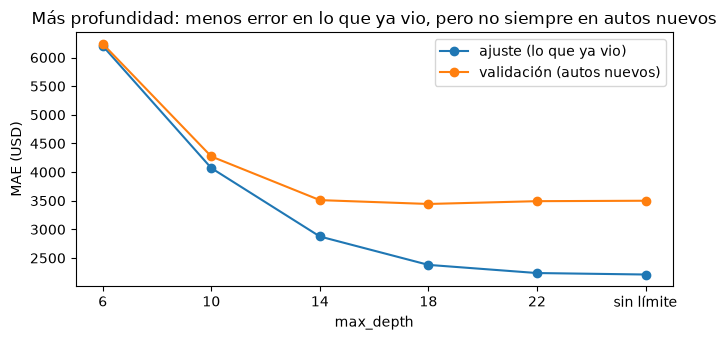

In [11]:
# ── Error por profundidad ──────────────────────────────────────────────────

fig, eje = plt.subplots(figsize=(7, 3.5))
etiquetas = tabla_profundidad['max_depth'].astype(str)
eje.plot(etiquetas, tabla_profundidad['MAE_ajuste'],     marker='o', label='ajuste (lo que ya vio)')
eje.plot(etiquetas, tabla_profundidad['MAE_validacion'], marker='o', label='validación (autos nuevos)')
eje.set_xlabel('max_depth')
eje.set_ylabel('MAE (USD)')
eje.set_title('Más profundidad: menos error en lo que ya vio, pero no siempre en autos nuevos')
eje.legend()
plt.tight_layout()
plt.show()

In [12]:
# ── Árbol final con la mejor profundidad ───────────────────────────────────

modelo_arbol = Pipeline([
    ('preparacion', prep_arbol),
    ('arbol', DecisionTreeRegressor(max_depth=MEJOR_PROFUNDIDAD, min_samples_leaf=5, random_state=SEMILLA)),
])

seg = entrenar(modelo_arbol)
metricas_arbol, pred_arbol = evaluar(f'Árbol de decisión (max_depth={mejor})', modelo_arbol, seg)

print()
print(f"Hojas del árbol: {modelo_arbol.named_steps['arbol'].get_n_leaves():,}")
print()
pd.Series(metricas_arbol).to_frame('valor')


Hojas del árbol: 16,082



,valor
modelo,Árbol de decisión (max_depth=18)
R2_entrenamiento,0.959728
R2_prueba,0.911682
MAE_prueba_USD,3340.482512
RMSE_prueba_USD,5727.03198
MAPE_prueba_pct,11.529417
seg_entrenamiento,4.225975
ms_por_1000_autos,10.334083
MB_joblib,0.612006


---
## PASO 7 — Comparación

In [13]:
# ── Tabla comparativa ──────────────────────────────────────────────────────

comparacion = pd.DataFrame([metricas_lineal, metricas_arbol]).set_index('modelo').T

formato = {'R2_entrenamiento': 3, 'R2_prueba': 3, 'MAE_prueba_USD': 0, 'RMSE_prueba_USD': 0,
           'MAPE_prueba_pct': 1, 'seg_entrenamiento': 2, 'ms_por_1000_autos': 2, 'MB_joblib': 2}
comparacion.apply(lambda fila: fila.round(formato[fila.name]), axis=1)

modelo,Regresión lineal,Árbol de decisión (max_depth=18)
R2_entrenamiento,0.887,0.960
R2_prueba,0.888,0.912
MAE_prueba_USD,3654.000,3340.000
RMSE_prueba_USD,6455.000,5727.000
MAPE_prueba_pct,11.600,11.500
seg_entrenamiento,22.310,4.230
ms_por_1000_autos,8.670,10.330
MB_joblib,0.010,0.610


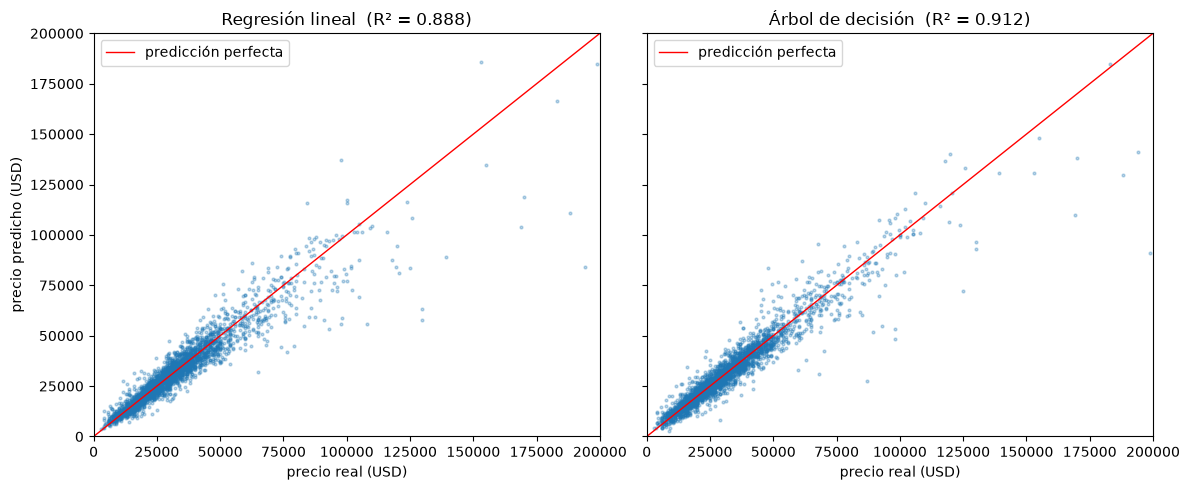

In [14]:
# ── Precio real vs. predicho (muestra de 3,000 autos de prueba) ────────────

muestra = np.random.default_rng(SEMILLA).choice(len(y_test), size=3000, replace=False)
limite  = [0, 200_000]

fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for eje, pred, titulo in [(ejes[0], pred_lineal, 'Regresión lineal'), (ejes[1], pred_arbol, 'Árbol de decisión')]:
    eje.scatter(y_test.iloc[muestra], pred[muestra], s=4, alpha=0.3)
    eje.plot(limite, limite, color='red', linewidth=1, label='predicción perfecta')
    eje.set_title(f'{titulo}  (R² = {r2_score(y_test, pred):.3f})')
    eje.set_xlabel('precio real (USD)')
    eje.set_xlim(limite); eje.set_ylim(limite)
    eje.legend()
ejes[0].set_ylabel('precio predicho (USD)')
plt.tight_layout()
plt.show()

In [15]:
# ── ¿En qué rango de precio se equivoca más cada modelo? ───────────────────

rangos = pd.cut(y_test, bins=[0, 15_000, 30_000, 50_000, 100_000, 200_000],
                labels=['$1k-15k', '$15k-30k', '$30k-50k', '$50k-100k', '$100k-200k'])

error_por_rango = pd.DataFrame({
    'anuncios'           : y_test.groupby(rangos, observed=True).size(),
    'MAE_lineal'         : (y_test - pred_lineal).abs().groupby(rangos, observed=True).mean(),
    'MAE_arbol'          : (y_test - pred_arbol).abs().groupby(rangos, observed=True).mean(),
    'MAPE_lineal_pct'    : ((y_test - pred_lineal).abs() / y_test).groupby(rangos, observed=True).mean() * 100,
    'MAPE_arbol_pct'     : ((y_test - pred_arbol).abs() / y_test).groupby(rangos, observed=True).mean() * 100,
}).round(1)

error_por_rango

,anuncios,MAE_lineal,MAE_arbol,MAPE_lineal_pct,MAPE_arbol_pct
price,,,,,
$1k-15k,5116,1802.1,2139.7,18.8,21.7
$15k-30k,16403,2351.6,2325.8,10.3,10.3
$30k-50k,11852,3742.5,3567.1,9.7,9.2
$50k-100k,4202,8213.3,6752.6,12.2,10.2
$100k-200k,396,30534.0,17897.8,23.1,13.6


---
## PASO 8 — ¿Qué aprendió cada modelo?

- **Regresión lineal:** como se entrenó sobre `log(price)`, cada coeficiente se lee como un **cambio porcentual** en el precio: `(e^coef − 1) × 100`. Para las numéricas (estandarizadas) es el efecto de subir **una desviación estándar**.
- **Árbol:** la **importancia** de cada variable es cuánto reduce el error al usarla en sus preguntas (suman 1).

In [16]:
# ── Regresión lineal: efecto de las variables numéricas y sí/no ────────────

nombres = modelo_lineal.named_steps['preparacion'].get_feature_names_out()
coefs   = pd.Series(modelo_lineal.named_steps['regresion'].regressor_.coef_, index=nombres)

efecto = coefs[[n for n in nombres if not n.startswith('categoricas__')]]
efecto = ((np.exp(efecto) - 1) * 100).round(1).sort_values()
efecto.index = efecto.index.str.replace('numericas__', '').str.replace('booleanas__', '')

efecto.to_frame('cambio_en_precio_pct')

,cambio_en_precio_pct
age,-22.0
mileage,-16.3
mpg_highway,-4.2
accidents_or_damage,-4.0
one_owner,-0.1
mileage_per_year,0.5
mpg_city,1.2
cylinders,1.5
personal_use_only,1.7
turbo,12.6


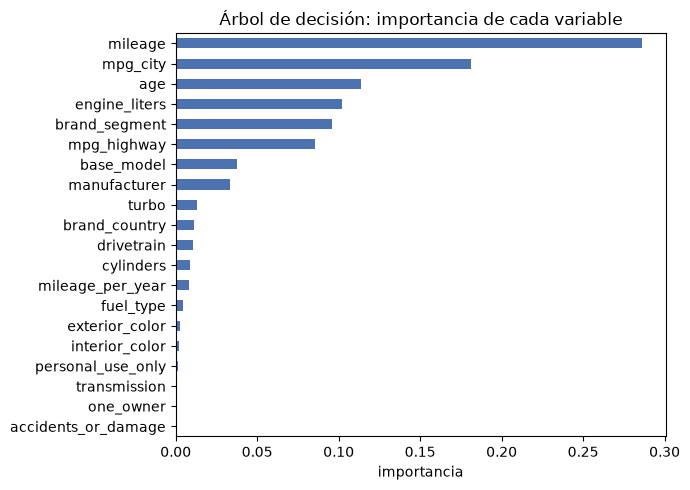

In [17]:
# ── Árbol: importancia de cada variable ────────────────────────────────────

importancia = pd.Series(modelo_arbol.named_steps['arbol'].feature_importances_,
                        index=CATEGORICAS + NUMERICAS + BOOLEANAS).sort_values()

fig, eje = plt.subplots(figsize=(7, 5))
importancia.plot.barh(ax=eje, color='#4C72B0')
eje.set_title('Árbol de decisión: importancia de cada variable')
eje.set_xlabel('importancia')
plt.tight_layout()
plt.show()

---
## PASO 9 — Prueba con un auto de ejemplo

Así usará la app el modelo: el usuario captura las características y el `Pipeline` hace todo lo demás.

In [18]:
# ── Un auto de ejemplo: Toyota RAV4 de 4 años con 45,000 millas ────────────

ejemplo = pd.DataFrame([{
    'manufacturer': 'Toyota', 'base_model': 'RAV4', 'brand_country': 'Japan', 'brand_segment': 'Mainstream',
    'transmission': 'Automatic', 'drivetrain': 'AWD', 'fuel_type': 'Gasoline',
    'exterior_color': 'White', 'interior_color': 'Black',
    'age': 4, 'mileage': 45_000, 'mileage_per_year': 45_000 // 4,
    'engine_liters': 2.5, 'cylinders': 4, 'mpg_city': 27, 'mpg_highway': 35,
    'turbo': 0, 'accidents_or_damage': 0, 'one_owner': 1, 'personal_use_only': 1,
}])[CATEGORICAS + NUMERICAS + BOOLEANAS]

# Referencia: precio mediano real de RAV4 de 4 años con 30k-60k millas
referencia = datos.query("base_model == 'RAV4' and age == 4 and 30000 <= mileage <= 60000")['price']

print()
print(f'Regresión lineal  : ${modelo_lineal.predict(ejemplo)[0]:,.0f}')
print(f'Árbol de decisión : ${modelo_arbol.predict(ejemplo)[0]:,.0f}')
print(f'Mediana real      : ${referencia.median():,.0f}  ({len(referencia)} anuncios parecidos)')
print()


Regresión lineal  : $29,123
Árbol de decisión : $29,945
Mediana real      : $30,451  (155 anuncios parecidos)



---
## PASO 10 — Coherencia: ¿la predicción se comporta como espera el usuario?

Las métricas miden el error **promedio**, pero en la app el usuario **mueve un control** y mira cómo cambia el precio. Un buen modelo para el formulario debe ser **coherente**:

- Más millaje o más antigüedad → el precio **baja** (nunca sube).
- Un accidente → el precio **baja**.

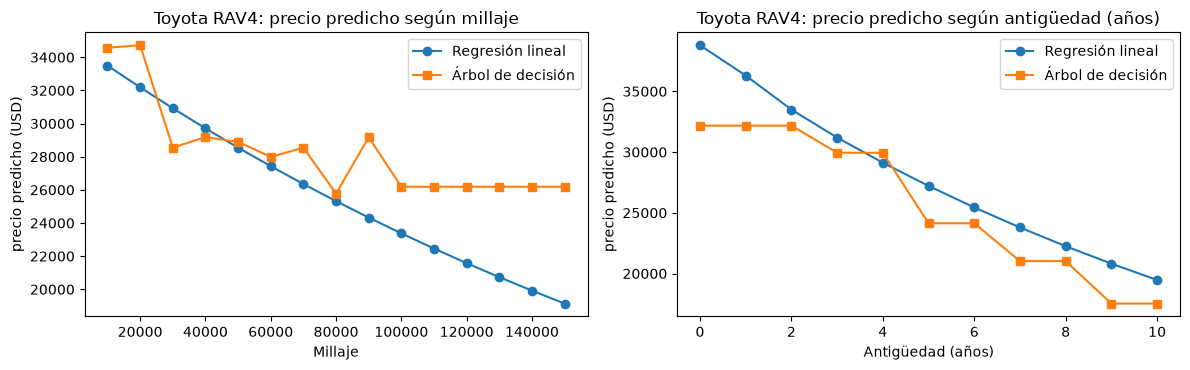

In [19]:
# ── El mismo RAV4 con distinto millaje y distinta antigüedad ───────────────

def variar(columna, valores):
    '''Copia el auto de ejemplo cambiando una columna (y recalcula mileage_per_year).'''
    filas = ejemplo.loc[ejemplo.index.repeat(len(valores))].reset_index(drop=True)
    filas[columna] = valores
    filas['mileage_per_year'] = (filas['mileage'] / filas['age'].clip(lower=1)).round()
    return filas

por_millaje = variar('mileage', list(range(10_000, 150_001, 10_000)))
por_edad    = variar('age', list(range(0, 11)))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
for eje, filas, col, titulo in [(ejes[0], por_millaje, 'mileage', 'Millaje'), (ejes[1], por_edad, 'age', 'Antigüedad (años)')]:
    eje.plot(filas[col], modelo_lineal.predict(filas), marker='o', label='Regresión lineal')
    eje.plot(filas[col], modelo_arbol.predict(filas),  marker='s', label='Árbol de decisión')
    eje.set_title(f'Toyota RAV4: precio predicho según {titulo.lower()}')
    eje.set_xlabel(titulo)
    eje.set_ylabel('precio predicho (USD)')
    eje.legend()
plt.tight_layout()
plt.show()

In [20]:
# ── En 300 autos de prueba: ¿agregar 20,000 millas o un accidente sube el precio? ──

rng      = np.random.default_rng(SEMILLA)
muestra  = X_test.iloc[rng.choice(len(X_test), size=300, replace=False)].reset_index(drop=True)

mas_millas = muestra.copy()
mas_millas['mileage']         += 20_000
mas_millas['mileage_per_year'] = (mas_millas['mileage'] / mas_millas['age'].clip(lower=1)).round()

sin_accidente = muestra[muestra['accidents_or_damage'] == 0]
con_accidente = sin_accidente.assign(accidents_or_damage=1)

coherencia = pd.DataFrame({
    modelo: {
        '+20k millas sube el precio (de 300)'           : int((m.predict(mas_millas) > m.predict(muestra) + 1).sum()),
        '+20k millas no cambia el precio (de 300)'      : int((np.abs(m.predict(mas_millas) - m.predict(muestra)) <= 1).sum()),
        f'accidente sube o no cambia el precio (de {len(sin_accidente)})':
            int((m.predict(con_accidente) >= m.predict(sin_accidente) - 1).sum()),
    }
    for modelo, m in [('Regresión lineal', modelo_lineal), ('Árbol de decisión', modelo_arbol)]
})

coherencia

,Regresión lineal,Árbol de decisión
+20k millas sube el precio (de 300),0,49
+20k millas no cambia el precio (de 300),0,30
accidente sube o no cambia el precio (de 222),0,197


**Lectura:** el árbol predice por **escalones**: los autos parecidos caen en la misma hoja y reciben el mismo precio. Por eso, al mover el millaje, su predicción a veces **sube** o se queda **fija**, y un accidente muchas veces **no cambia** nada. La regresión lineal responde siempre en la dirección lógica, porque cada variable tiene un solo efecto (su coeficiente).

---
## PASO 11 — Decisión y guardado del modelo

| Criterio | Regresión lineal | Árbol de decisión |
|---|---|---|
| Precisión (R², MAE, MAPE) | Un poco menor | Un poco mayor |
| Sobreajuste (R² entrenamiento vs. prueba) | **Ninguno** | Memoriza parte de los datos |
| Coherencia en el formulario | **Siempre lógica** | Escalones: a veces sube con más millaje o ignora un accidente |
| Explicación para el usuario | **Cada variable tiene un efecto en %** (PASO 8) | Miles de reglas sí/no |
| Tamaño del archivo | **~10 KB** | ~0.6 MB |

**Decisión: regresión lineal.** La diferencia de precisión es pequeña (los MAPE de los dos rondan el 11.5 %), y a cambio el modelo responde de forma coherente cuando el usuario cambia una característica, se explica en una frase ("cada año de antigüedad baja el precio cierto %") y es el más ligero.

Se guarda el modelo **entrenado con el 80 % de entrenamiento**, así las métricas que muestra la app son exactamente las de la prueba de este notebook. Junto al modelo se guardan:

| Archivo | Para qué |
|---|---|
| `streamlit/modelo.joblib` | El `Pipeline` completo (preparación + regresión) |
| `streamlit/modelo_info.json` | Variables de entrada, métricas de prueba y versiones de las librerías, para mostrarlos en la app |
| `streamlit/real_vs_predicho.png` | Gráfica de precio real vs. predicho, para la app |

In [21]:
# ── Guardar el modelo elegido y su información ─────────────────────────────

import json

os.makedirs(STREAMLIT_PATH, exist_ok=True)

MODELO_PATH  = f'{STREAMLIT_PATH}/modelo.joblib'
INFO_PATH    = f'{STREAMLIT_PATH}/modelo_info.json'
GRAFICA_PATH = f'{STREAMLIT_PATH}/real_vs_predicho.png'

joblib.dump(modelo_lineal, MODELO_PATH, compress=3)

info = {
    'modelo'          : 'Regresión lineal sobre log(price)',
    'objetivo'        : OBJETIVO,
    'categoricas'     : CATEGORICAS,
    'numericas'       : NUMERICAS,
    'booleanas'       : BOOLEANAS,
    'filas_entrenamiento': len(X_train),
    'filas_prueba'    : len(X_test),
    'metricas_prueba' : {'R2'  : round(metricas_lineal['R2_prueba'], 3),
                         'MAE' : round(metricas_lineal['MAE_prueba_USD']),
                         'RMSE': round(metricas_lineal['RMSE_prueba_USD']),
                         'MAPE': round(metricas_lineal['MAPE_prueba_pct'], 1)},
    'efecto_pct'      : efecto.to_dict(),
    'versiones'       : {'scikit-learn': sklearn.__version__, 'joblib': joblib.__version__,
                         'pandas': pd.__version__, 'numpy': np.__version__},
}
with open(INFO_PATH, 'w', encoding='utf-8') as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

# Gráfica real vs. predicho para la app
fig, eje = plt.subplots(figsize=(6, 5))
eje.scatter(y_test.iloc[muestra_graf := np.random.default_rng(SEMILLA).choice(len(y_test), 3000, replace=False)],
            pred_lineal[muestra_graf], s=4, alpha=0.3)
eje.plot([0, 200_000], [0, 200_000], color='red', linewidth=1, label='predicción perfecta')
eje.set_xlim(0, 200_000); eje.set_ylim(0, 200_000)
eje.set_xlabel('precio real (USD)'); eje.set_ylabel('precio predicho (USD)')
eje.set_title(f"Regresión lineal: real vs. predicho (R² = {info['metricas_prueba']['R2']})")
eje.legend()
plt.tight_layout()
fig.savefig(GRAFICA_PATH, dpi=110)
plt.close(fig)

print()
for ruta in (MODELO_PATH, INFO_PATH, GRAFICA_PATH):
    print(f'  {ruta_relativa(ruta):<35} {tamano_mb(ruta) * 1024:8.1f} KB')
print()


  streamlit/modelo.joblib                 11.2 KB
  streamlit/modelo_info.json               1.1 KB
  streamlit/real_vs_predicho.png          52.8 KB



In [22]:
# ── Comprobar: cargar el archivo y predecir igual que el modelo en memoria ─

modelo_cargado = joblib.load(MODELO_PATH)

iguales = np.allclose(modelo_cargado.predict(X_test), pred_lineal)

print()
print(f'¿El modelo cargado predice igual que el original? {iguales}')
print(f'RAV4 de ejemplo con el modelo cargado: ${modelo_cargado.predict(ejemplo)[0]:,.0f}')
print()


¿El modelo cargado predice igual que el original? True
RAV4 de ejemplo con el modelo cargado: $29,123



> **Importante para la app:** un `.joblib` se debe cargar con **la misma versión de scikit-learn** con la que se guardó (está en `modelo_info.json`). Por eso `streamlit/requirements.txt` fija esa versión.

---
### Resumen

| Paso | Qué hicimos |
|---|---|
| 1 | Leímos `serving.db` uniendo `fact_listings` con sus dimensiones |
| 2 | Elegimos 20 variables de entrada y excluimos las redundantes, las informativas y las que causarían *leakage* |
| 3 | Partimos 80 % entrenamiento / 20 % prueba |
| 4 | Preparamos las variables con un `Pipeline` por modelo |
| 5 | Entrenamos una **regresión lineal** sobre `log(price)` |
| 6 | Elegimos la profundidad del **árbol de decisión** con validación y lo entrenamos |
| 7 | Comparamos métricas, tamaño, velocidad y error por rango de precio |
| 8 | Revisamos qué aprendió cada modelo |
| 9 | Probamos ambos con un auto de ejemplo |
| 10 | Medimos la **coherencia** de cada modelo al cambiar millaje, antigüedad o accidentes |
| 11 | **Elegimos la regresión lineal** y la guardamos en `streamlit/` con su información y su gráfica |

**Siguiente paso:** `streamlit/app.py`, que carga `modelo.joblib` y consulta `serving.db`.